# Stage 2: NLOS Signal Quality Classifier (LNN encoder)

Stage 2 of the pipeline. For every NLOS sample it decides whether the CIR is a clean single bounce that Stage 3 can correct (label 0, correctable) or a multi-bounce signal that it should leave alone (label 1, challenging). The paper calls the two classes single-bounce and multi-bounce.

The labels come from two checks against the geometric ground truth `bounce_path_idx`:

| Check | What it measures |
|-------|------------------|
| Bounce dominance | largest amplitude within 3 samples of `bounce_path_idx`, divided by the largest amplitude in the CIR ROI |
| Peak count | number of prominent peaks in the CIR ROI (prominence 0.2, minimum distance 5) |

A sample is correctable when the bounce dominance is at least 50% and there are at most 2 peaks. Otherwise it is challenging.

The labels are built from the floor-plan geometry and the CIR peak structure, while the random forest only sees the 64-dim LNN embeddings from the frozen Stage 1 encoder, so it never gets the labelling features directly.

Pipeline: Stage 1 (LNN, LOS/NLOS) -> **Stage 2 (LNN embeddings -> RF, signal quality)** -> Stage 3 (bounce distance prediction)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks
from scipy.stats import kurtosis as scipy_kurtosis
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve, auc
)
import os
import re

# Configuration
CONFIG = {
    # ROI alignment
    "search_start": 740,
    "search_end": 810,
    # Peak detection (morphological CIR quality)
    "peak_prominence": 0.20,
    "peak_min_distance": 5,
    "dominant_path_max_peaks": 2,
    # Geometric bounce dominance (amplitude ratio)
    "bounce_search_window": 3,
    "dominance_threshold": 0.50,
    # Random Forest
    "n_estimators": 200,
    "max_depth": None,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    # Split
    "test_ratio": 0.30,
    "seed": 42,
}

np.random.seed(CONFIG["seed"])
print(f"Config: {CONFIG}")
print(f"\nLabel strategy: MIXTURE (geometric + morphological)")
print(f"  Criterion 1: bounce dominance (amplitude ratio) >= {CONFIG['dominance_threshold']:.0%}")
print(f"  Criterion 2: num_peaks <= {CONFIG['dominant_path_max_peaks']}")
print(f"  Correctable (0): BOTH conditions met")
print(f"  Challenging (1): either condition violated")
print(f"  Model input:   64-dim LNN embeddings → RF classifier")

Config: {'search_start': 740, 'search_end': 810, 'peak_prominence': 0.2, 'peak_min_distance': 5, 'dominant_path_max_peaks': 2, 'bounce_search_window': 3, 'dominance_threshold': 0.5, 'n_estimators': 200, 'max_depth': None, 'min_samples_split': 5, 'min_samples_leaf': 2, 'test_ratio': 0.3, 'seed': 42}

Label strategy: MIXTURE (geometric + morphological)
  Criterion 1: bounce dominance (amplitude ratio) >= 50%
  Criterion 2: num_peaks <= 2
  Correctable (0): BOTH conditions met
  Challenging (1): either condition violated
  Model input:   64-dim LNN embeddings → RF classifier


---
## 1. Data Loading and Labels

1. Load the NLOS samples from the combined dataset.
2. Label each sample from the geometric ground truth and the CIR shape:
   - bounce dominance, using the known `bounce_path_idx` (from the TX -> reflector -> RX geometry)
   - peak count in the CIR ROI
   - correctable when the bounce dominance is at least 50% and there are at most 2 peaks, challenging otherwise

All NLOS scenarios are single-bounce by geometry (TX -> wall -> RX). The two checks look at different things: whether the energy arrives where the geometry says it should, and how cluttered the multipath is.

In [2]:
# ROI alignment
def get_roi_alignment(sig, search_start=CONFIG["search_start"],
                      search_end=CONFIG["search_end"]):
    """Find leading edge by backtracking from peak."""
    region = sig[search_start:search_end]
    if len(region) == 0:
        return np.argmax(sig)

    peak_local = np.argmax(region)
    peak_idx = search_start + peak_local
    peak_val = sig[peak_idx]

    noise_section = sig[:search_start]
    if len(noise_section) > 10:
        noise_mean = np.mean(noise_section)
        noise_std = np.std(noise_section)
        threshold = max(noise_mean + 3 * noise_std, 0.05 * peak_val)
    else:
        threshold = 0.05 * peak_val

    leading_edge = peak_idx
    for i in range(peak_idx, max(search_start - 20, 0), -1):
        if sig[i] < threshold:
            leading_edge = i + 1
            break

    return leading_edge


# Count peaks in CIR ROI
def count_peaks_in_roi(sig, leading_edge, config=CONFIG):
    """Count prominent peaks in CIR ROI (120 samples from leading edge)."""
    roi_start = max(0, leading_edge - 5)
    roi_end = min(len(sig), leading_edge + 120)
    roi = sig[roi_start:roi_end]
    if len(roi) == 0 or np.max(roi) == 0:
        return 0
    roi_norm = roi / np.max(roi)
    peaks, _ = find_peaks(
        roi_norm,
        prominence=config["peak_prominence"],
        distance=config["peak_min_distance"]
    )
    return len(peaks)


# Geometric bounce dominance (amplitude ratio)
def compute_bounce_dominance(sig, leading_edge, bounce_path_idx,
                              window=CONFIG["bounce_search_window"]):
    """
    Amplitude ratio: peak amplitude near bounce position / strongest peak in ROI.
    Returns 0-1. High value = bounce peak is the dominant peak.
    Not affected by ROI size or tail energy dilution.
    """
    roi_start = max(0, leading_edge - 5)
    roi_end = min(len(sig), leading_edge + 120)
    roi = sig[roi_start:roi_end]

    if len(roi) == 0 or np.max(roi) == 0:
        return 0.0

    # Strongest peak amplitude in entire ROI
    strongest_amp = float(np.max(roi))

    # Peak amplitude near geometric bounce position (+/-window samples)
    bounce_idx = int(round(bounce_path_idx))
    b_start = max(0, bounce_idx - window)
    b_end = min(len(sig), bounce_idx + window + 1)

    if b_start >= b_end:
        return 0.0

    bounce_amp = float(np.max(sig[b_start:b_end]))
    return bounce_amp / strongest_amp


# Strongest peak power in ROI
def get_strongest_peak_power(sig, leading_edge):
    """Max CIR amplitude in ROI after RXPACC normalization."""
    roi_start = max(0, leading_edge - 5)
    roi_end = min(len(sig), leading_edge + 120)
    roi = sig[roi_start:roi_end]
    if len(roi) == 0:
        return 0.0
    return float(np.max(roi))


# Load NLOS data and compute the mixture labels
def load_nlos_features(filepath="../dataset/channels/combined_uwb_dataset.csv"):
    """
    Load NLOS samples and compute mixture quality labels.
    Correctable: bounce dominance (amplitude ratio) >= threshold AND num_peaks <= max_peaks.
    Challenging: otherwise.
    Returns: (raw_sigs, leading_edges, nlos_df, quality_labels, num_peaks, bounce_dominance, strongest_peak_power)
    """
    print(f"Loading: {filepath}")
    df = pd.read_csv(filepath)

    # Filter NLOS only
    nlos_df = df[df["Label"] == 1].reset_index(drop=True)
    print(f"  Total samples: {len(df)}, NLOS samples: {len(nlos_df)}")

    cir_cols = sorted(
        [c for c in df.columns if c.startswith('CIR')],
        key=lambda x: int(x.replace('CIR', ''))
    )

    raw_sigs = []
    leading_edges = []
    num_peaks_list = []
    bounce_dom_list = []
    strongest_peak_power_list = []

    for idx, row in nlos_df.iterrows():
        sig = pd.to_numeric(row[cir_cols], errors='coerce').fillna(0).astype(float).values

        # RXPACC normalization
        rxpacc_col = 'RXPACC' if 'RXPACC' in row.index else 'RX_PACC'
        rxpacc = float(row.get(rxpacc_col, 128.0))
        if rxpacc > 0:
            sig = sig / rxpacc

        le = get_roi_alignment(sig)
        raw_sigs.append(sig)
        leading_edges.append(le)

        # Morphological: peak count
        num_peaks_list.append(count_peaks_in_roi(sig, le))

        # Geometric: bounce dominance (amplitude ratio)
        bpi = float(row.get('bounce_path_idx', np.nan))
        if np.isnan(bpi):
            bounce_dom_list.append(0.0)
        else:
            bounce_dom_list.append(compute_bounce_dominance(sig, le, bpi))

        # Strongest peak power
        strongest_peak_power_list.append(get_strongest_peak_power(sig, le))

    num_peaks = np.array(num_peaks_list, dtype=int)
    bounce_dominance = np.array(bounce_dom_list, dtype=float)
    strongest_peak_power = np.array(strongest_peak_power_list, dtype=float)

    # Mixture label
    dom_thresh = CONFIG["dominance_threshold"]
    peak_thresh = CONFIG["dominant_path_max_peaks"]
    is_correctable = (bounce_dominance >= dom_thresh) & (num_peaks <= peak_thresh)
    quality_labels = np.where(is_correctable, 0, 1).astype(int)

    n_correctable = int(np.sum(quality_labels == 0))
    n_challenging = int(np.sum(quality_labels == 1))

    print(f"\n  Mixture labeling (amplitude ratio >= {dom_thresh:.0%} AND peaks <= {peak_thresh}):")
    print(f"    {'─' * 50}")
    print(f"    Correctable (clean bounce):     {n_correctable} ({100*n_correctable/len(quality_labels):.1f}%)")
    print(f"    Challenging (multipath/noisy):   {n_challenging} ({100*n_challenging/len(quality_labels):.1f}%)")
    print(f"    {'─' * 50}")
    print(f"    Bounce dominance stats — mean: {bounce_dominance.mean():.3f}, "
          f"median: {np.median(bounce_dominance):.3f}")
    print(f"    Peak count stats — mean: {num_peaks.mean():.2f}, "
          f"max: {num_peaks.max()}")
    print(f"    Strongest peak power stats — mean: {strongest_peak_power.mean():.4f}, "
          f"min: {strongest_peak_power.min():.4f}, max: {strongest_peak_power.max():.4f}")

    return (np.array(raw_sigs), np.array(leading_edges), nlos_df,
            quality_labels, num_peaks, bounce_dominance, strongest_peak_power)


raw_sigs, leading_edges, nlos_df, quality_labels, num_peaks, bounce_dominance, strongest_peak_power = load_nlos_features()

Loading: ../dataset/channels/combined_uwb_dataset.csv


  Total samples: 3600, NLOS samples: 1800



  Mixture labeling (amplitude ratio >= 50% AND peaks <= 2):
    ──────────────────────────────────────────────────
    Correctable (clean bounce):     506 (28.1%)
    Challenging (multipath/noisy):   1294 (71.9%)
    ──────────────────────────────────────────────────
    Bounce dominance stats — mean: 0.778, median: 0.890
    Peak count stats — mean: 4.71, max: 12
    Strongest peak power stats — mean: 35.2407, min: 5.3226, max: 65.2119


---
## 2. Labelling Rule

`bounce_path_idx` is the CIR index where the single-bounce path should arrive, computed from the TX -> reflector -> RX distances measured on site.

1. Bounce dominance: the largest amplitude within 3 samples of `bounce_path_idx`, divided by the largest amplitude in the ROI.
   - at least 50%: the bounce is the dominant arrival
   - below 50%: other multipath components are stronger
2. Peak count: the number of prominent peaks in the ROI.
   - at most 2: a clean signal
   - more than 2: a complex multipath channel

A sample is correctable only if both conditions hold.

Mixture labeling (amplitude ratio >= 50% AND peaks <= 2):
  Correctable: 506 (28.1%)
  Challenging: 1294 (71.9%)


C:\Users\preca\AppData\Local\Temp\ipykernel_11576\1016646930.py:84: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=unique_groups, patch_artist=True)


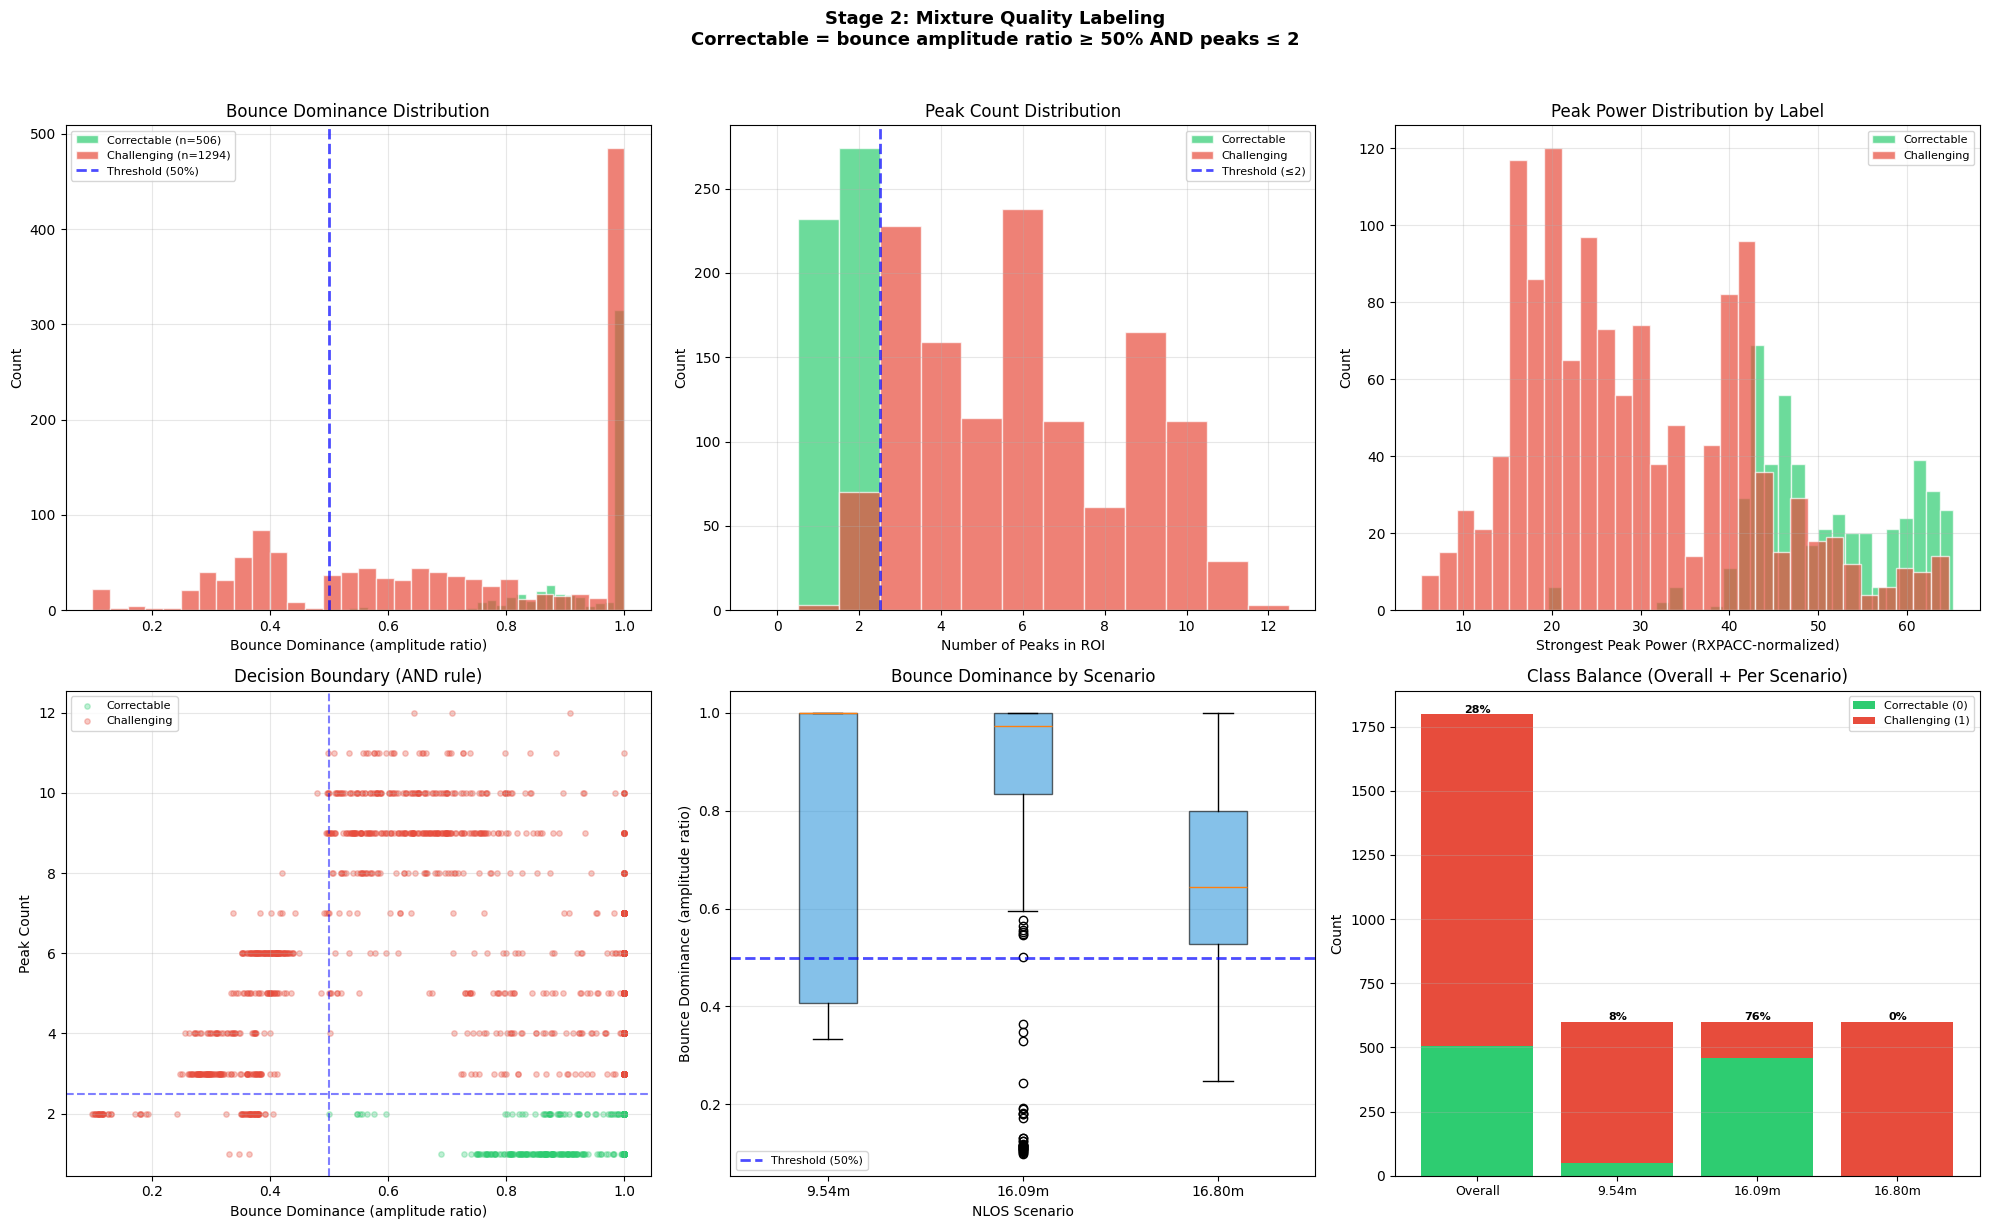

In [3]:
# Mixture labeling visualization
dom_thresh = CONFIG["dominance_threshold"]
peak_thresh = CONFIG["dominant_path_max_peaks"]
n_correctable = int(np.sum(quality_labels == 0))
n_challenging = int(np.sum(quality_labels == 1))

print(f"Mixture labeling (amplitude ratio >= {dom_thresh:.0%} AND peaks <= {peak_thresh}):")
print(f"  Correctable: {n_correctable} ({100*n_correctable/len(quality_labels):.1f}%)")
print(f"  Challenging: {n_challenging} ({100*n_challenging/len(quality_labels):.1f}%)")

fig, axs = plt.subplots(2, 3, figsize=(20, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

correctable_mask = quality_labels == 0
challenging_mask = quality_labels == 1

# Bounce dominance histogram
ax = axs[0, 0]
ax.hist(bounce_dominance[correctable_mask], bins=30, color='#2ecc71', alpha=0.7,
        label=f'Correctable (n={n_correctable})', edgecolor='white')
ax.hist(bounce_dominance[challenging_mask], bins=30, color='#e74c3c', alpha=0.7,
        label=f'Challenging (n={n_challenging})', edgecolor='white')
ax.axvline(dom_thresh, color='blue', ls='--', lw=2, alpha=0.7,
           label=f'Threshold ({dom_thresh:.0%})')
ax.set_xlabel('Bounce Dominance (amplitude ratio)')
ax.set_ylabel('Count')
ax.set_title('Bounce Dominance Distribution')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Peak count histogram
ax = axs[0, 1]
max_peaks = int(num_peaks.max())
bins_peaks = np.arange(-0.5, max_peaks + 1.5, 1)
ax.hist(num_peaks[correctable_mask], bins=bins_peaks, color='#2ecc71', alpha=0.7,
        label='Correctable', edgecolor='white')
ax.hist(num_peaks[challenging_mask], bins=bins_peaks, color='#e74c3c', alpha=0.7,
        label='Challenging', edgecolor='white')
ax.axvline(peak_thresh + 0.5, color='blue', ls='--', lw=2, alpha=0.7,
           label=f'Threshold (≤{peak_thresh})')
ax.set_xlabel('Number of Peaks in ROI')
ax.set_ylabel('Count')
ax.set_title('Peak Count Distribution')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Strongest peak power by label
ax = axs[0, 2]
ax.hist(strongest_peak_power[correctable_mask], bins=30, color='#2ecc71', alpha=0.7,
        label='Correctable', edgecolor='white')
ax.hist(strongest_peak_power[challenging_mask], bins=30, color='#e74c3c', alpha=0.7,
        label='Challenging', edgecolor='white')
ax.set_xlabel('Strongest Peak Power (RXPACC-normalized)')
ax.set_ylabel('Count')
ax.set_title('Peak Power Distribution by Label')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Scatter: dominance vs peak count
ax = axs[1, 0]
ax.scatter(bounce_dominance[correctable_mask], num_peaks[correctable_mask],
           c='#2ecc71', alpha=0.3, s=15, label='Correctable')
ax.scatter(bounce_dominance[challenging_mask], num_peaks[challenging_mask],
           c='#e74c3c', alpha=0.3, s=15, label='Challenging')
ax.axvline(dom_thresh, color='blue', ls='--', lw=1.5, alpha=0.5)
ax.axhline(peak_thresh + 0.5, color='blue', ls='--', lw=1.5, alpha=0.5)
ax.set_xlabel('Bounce Dominance (amplitude ratio)')
ax.set_ylabel('Peak Count')
ax.set_title('Decision Boundary (AND rule)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Per-scenario bounce dominance boxplot
ax = axs[1, 1]
source_files = nlos_df['Source_File'].values
groups = []
for sf in source_files:
    match = re.search(r'([\d.]+)m_nlos', str(sf))
    groups.append(match.group(1) + 'm' if match else 'unknown')
groups = np.array(groups)
unique_groups = sorted(set(groups), key=lambda x: float(x.replace('m', '')))

box_data = [bounce_dominance[groups == g] for g in unique_groups]
bp = ax.boxplot(box_data, labels=unique_groups, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('#3498db')
    patch.set_alpha(0.6)
ax.axhline(dom_thresh, color='blue', ls='--', lw=2, alpha=0.7,
           label=f'Threshold ({dom_thresh:.0%})')
ax.set_xlabel('NLOS Scenario')
ax.set_ylabel('Bounce Dominance (amplitude ratio)')
ax.set_title('Bounce Dominance by Scenario')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')

# Class balance: overall + per scenario
ax = axs[1, 2]
x_pos = np.arange(len(unique_groups) + 1)
labels_bar = ['Overall'] + unique_groups
correctable_counts = [n_correctable]
challenging_counts = [n_challenging]
for g in unique_groups:
    mask = groups == g
    correctable_counts.append(int(np.sum(quality_labels[mask] == 0)))
    challenging_counts.append(int(np.sum(quality_labels[mask] == 1)))

ax.bar(x_pos, correctable_counts, color='#2ecc71', label='Correctable (0)')
ax.bar(x_pos, challenging_counts, bottom=correctable_counts,
       color='#e74c3c', label='Challenging (1)')
ax.set_xticks(x_pos)
ax.set_xticklabels(labels_bar, fontsize=9)
ax.set_ylabel('Count')
ax.set_title('Class Balance (Overall + Per Scenario)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')

for i in range(len(x_pos)):
    total = correctable_counts[i] + challenging_counts[i]
    pct = 100 * correctable_counts[i] / total if total > 0 else 0
    ax.text(x_pos[i], total + 5, f'{pct:.0f}%', ha='center', fontsize=8, fontweight='bold')

plt.suptitle(f'Stage 2: Mixture Quality Labeling\n'
             f'Correctable = bounce amplitude ratio ≥ {dom_thresh:.0%} AND peaks ≤ {peak_thresh}',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 3. LNN Encoder and Embeddings

The trained Stage 1 `DualCircuit_PI_HLNN` encoder is frozen and used as a feature extractor. Each circuit's hidden trajectory is averaged over time, $(1/T) \sum_t h(t)$, and the two are concatenated into a 64-dim embedding, with no learned readout. Both circuits start from zeros.

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class PILiquidCell(nn.Module):
    """Liquid time-constant cell of PL-MIND, as in stage1_pi_hlnn.ipynb (Eqs. 2-5 of the paper)."""
    def __init__(self, input_size, hidden_size, ode_unfolds=6):
        super().__init__()
        self.hidden_size = hidden_size
        self.input_size  = input_size
        self.ode_unfolds = ode_unfolds

        # Per-neuron CIR dynamics
        self.signal_decay = nn.Parameter(torch.empty(hidden_size).uniform_(0.001, 1.0))   # lambda
        self.noise_floor  = nn.Parameter(torch.empty(hidden_size).uniform_(-0.2, 0.2))    # v0
        self.smoothing    = nn.Parameter(torch.empty(hidden_size).uniform_(0.4, 0.6))      # k

        # Signal strength S(t): weighted gated feedback between hidden units
        self.coupling_w        = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(0.001, 1.0))  # w_j in S(t)
        self.signal_target     = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(-0.2, 0.2))   # v_target
        self.activation_center = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(0.3, 0.8))    # sigma_j gate centre
        self.activation_width  = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(3, 8))        # sigma_j gate width

        # Input coupling: CIR sample x(t) -> hidden state, I(x(t))
        self.input_coupling_w = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(0.001, 1.0))
        self.input_center     = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(0.3, 0.8))
        self.input_width      = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(3, 8))

    def forward(self, x_t, h_prev, dt=1.0):
        # Ensure positivity via softplus
        decay     = F.softplus(self.signal_decay)      # lambda > 0
        smoothing = F.softplus(self.smoothing)          # k > 0
        coupling  = F.softplus(self.coupling_w)         # w_j > 0
        input_w   = F.softplus(self.input_coupling_w)   # input coupling > 0

        # I(x(t)): how strongly each CIR sample drives the hidden state
        input_gate    = torch.sigmoid(self.input_width * (x_t.unsqueeze(-1) - self.input_center))
        input_current = (input_w * input_gate * x_t.unsqueeze(-1)).sum(dim=1)   # I(x(t))

        # Eq. 5: Euler sub-steps of the CIR ODE
        smoothing_t = smoothing / (dt / self.ode_unfolds)   # k scaled by sub-step size
        v = h_prev   # v(t): current CIR state

        for _ in range(self.ode_unfolds):
            # Signal strength gate: sigma_j(v) = sigmoid(activation_width * (v - activation_center))
            pattern_gate = torch.sigmoid(
                self.activation_width.unsqueeze(0) * (v.unsqueeze(2) - self.activation_center.unsqueeze(0))
            )
            # Eq. 2: signal strength S(t) = sum_j w_j * sigma_j(v)
            gated_coupling = coupling.unsqueeze(0) * pattern_gate

            # S(t) * v_target and S(t) terms
            coupling_num = (gated_coupling * self.signal_target.unsqueeze(0)).sum(dim=1)  # sum_j w_j * sigma_j * v_target
            coupling_den = gated_coupling.sum(dim=1)                                       # S(t) = sum_j w_j * sigma_j

            # Eq. 4, semi-implicit Euler: v_new = (k*v + lambda*v0 + S*v_target + I) / (k + lambda + S + eps)
            numerator   = smoothing_t * v + decay * self.noise_floor + coupling_num + input_current
            denominator = smoothing_t + decay + coupling_den + 1e-8
            v = numerator / denominator
            v = torch.clamp(v, -1.0, 1.0)

        # Eq. 3: adaptive time constant tau = k / (lambda + S(t))
        tau = smoothing / (decay + coupling_den + 1e-8)
        return v, tau


class DualCircuit_PI_HLNN(nn.Module):
    """
    Dual-circuit PI-HLNN encoder (PL-MIND in the paper).
    Both circuits start from h0 = zeros(32) and the readout averages the
    hidden states over time.
    """
    def __init__(self, input_size=1, hidden_size=32, dropout=0.2, ode_unfolds=6):
        super().__init__()
        self.hidden_size = hidden_size

        self.cell_los  = PILiquidCell(input_size, hidden_size, ode_unfolds)
        self.cell_nlos = PILiquidCell(input_size, hidden_size, ode_unfolds)

        self.P_nlos2los = nn.Linear(hidden_size, hidden_size, bias=False)
        self.P_los2nlos = nn.Linear(hidden_size, hidden_size, bias=False)

        self.gate_los  = nn.Linear(hidden_size * 2, hidden_size)
        self.gate_nlos = nn.Linear(hidden_size * 2, hidden_size)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 1),
            nn.Sigmoid()
        )

    def _run_circuits(self, x_seq):
        batch_size, seq_len, _ = x_seq.size()

        h_los  = torch.zeros(batch_size, self.hidden_size, device=x_seq.device)
        h_nlos = torch.zeros(batch_size, self.hidden_size, device=x_seq.device)

        los_states, nlos_states = [], []
        tau_los_sum  = torch.zeros_like(h_los)
        tau_nlos_sum = torch.zeros_like(h_nlos)
        tau_los_hist_list, tau_nlos_hist_list = [], []

        for t in range(seq_len):
            x_t = x_seq[:, t, :]

            proj_nlos_to_los = self.P_nlos2los(h_nlos)
            proj_los_to_nlos = self.P_los2nlos(h_los)

            g_los  = torch.sigmoid(self.gate_los( torch.cat([h_los,  proj_nlos_to_los], dim=1)))
            g_nlos = torch.sigmoid(self.gate_nlos(torch.cat([h_nlos, proj_los_to_nlos], dim=1)))

            h_los_in  = h_los  + g_los  * proj_nlos_to_los
            h_nlos_in = h_nlos + g_nlos * proj_los_to_nlos

            h_los,  tau_los  = self.cell_los( x_t, h_los_in)
            h_nlos, tau_nlos = self.cell_nlos(x_t, h_nlos_in)

            los_states.append(h_los.unsqueeze(1))
            nlos_states.append(h_nlos.unsqueeze(1))
            tau_los_sum  += tau_los
            tau_nlos_sum += tau_nlos
            tau_los_hist_list.append(tau_los.unsqueeze(1))
            tau_nlos_hist_list.append(tau_nlos.unsqueeze(1))

        los_all  = torch.cat(los_states,  dim=1)
        nlos_all = torch.cat(nlos_states, dim=1)
        tau_los_mean  = tau_los_sum  / seq_len
        tau_nlos_mean = tau_nlos_sum / seq_len
        tau_los_hist  = torch.cat(tau_los_hist_list,  dim=1)
        tau_nlos_hist = torch.cat(tau_nlos_hist_list, dim=1)
        return los_all, nlos_all, tau_los_hist, tau_nlos_hist, tau_los_mean, tau_nlos_mean

    def _pool_and_fuse(self, los_all, nlos_all):
        """Average each circuit's hidden trajectory over time and concatenate the two."""
        h_los_avg  = los_all.mean(dim=1)
        h_nlos_avg = nlos_all.mean(dim=1)
        return torch.cat([h_los_avg, h_nlos_avg], dim=1)

    def forward(self, x_seq, return_dynamics=False):
        los_all, nlos_all, tau_los_hist, tau_nlos_hist, tau_los_mean, tau_nlos_mean = \
            self._run_circuits(x_seq)
        h_fused = self._pool_and_fuse(los_all, nlos_all)
        pred = self.classifier(h_fused)
        if return_dynamics:
            return pred, los_all, nlos_all, tau_los_hist, tau_nlos_hist, tau_los_mean, tau_nlos_mean
        return pred, tau_los_mean, tau_nlos_mean

    def embed(self, x_seq):
        """Return 64-dim fused embedding for Stage 2/3."""
        los_all, nlos_all, _, _, _, _ = self._run_circuits(x_seq)
        return self._pool_and_fuse(los_all, nlos_all)


print(f"DualCircuit_PI_HLNN defined: {sum(p.numel() for p in DualCircuit_PI_HLNN().parameters()):,} params")
print(f"  Embedding dim: 64 (2 x 32)")
print(f"  Pooling: average-over-time (no attention — time-averaged ODE trajectory)")

DualCircuit_PI_HLNN defined: 16,897 params
  Embedding dim: 64 (2 x 32)
  Pooling: average-over-time (no attention — time-averaged ODE trajectory)


In [5]:
# Load the frozen Stage 1 encoder and extract embeddings
# Load Stage 1 config
_saved = torch.load("stage1_pi_hlnn_config.pt", map_location="cpu", weights_only=False)
STAGE1_CONFIG = _saved["config"]
print("STAGE1_CONFIG loaded from stage1_pi_hlnn_config.pt")
print(STAGE1_CONFIG)

EMBEDDING_DIM = STAGE1_CONFIG['hidden_size'] * 2  # 64 (2 circuits x 32)
EMBEDDING_NAMES = [f'LNN_h{i}' for i in range(EMBEDDING_DIM)]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def preprocess_cir_for_lnn(sig, leading_edge):
    """Convert a single RXPACC-normalized CIR + leading edge to 60-sample window."""
    PRE = STAGE1_CONFIG['pre_crop']
    TOTAL = STAGE1_CONFIG['total_len']
    start = max(0, leading_edge - PRE)
    end = start + TOTAL
    if end > len(sig):
        end = len(sig)
        start = max(0, end - TOTAL)
    crop = sig[start:end]
    if len(crop) < TOTAL:
        crop = np.pad(crop, (0, TOTAL - len(crop)), mode='constant')
    local_min, local_max = np.min(crop), np.max(crop)
    rng = local_max - local_min
    crop = (crop - local_min) / rng if rng > 0 else np.zeros(TOTAL)
    return crop


# Load the frozen Stage 1 encoder (DualCircuit_PI_HLNN)
lnn_encoder = DualCircuit_PI_HLNN(
    input_size=STAGE1_CONFIG['input_size'],
    hidden_size=STAGE1_CONFIG['hidden_size'],
    dropout=STAGE1_CONFIG['dropout'],
    ode_unfolds=STAGE1_CONFIG['ode_unfolds'],
).to(device)

checkpoint_path = 'stage1_pi_hlnn_best.pt'
lnn_encoder.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
lnn_encoder.eval()
for param in lnn_encoder.parameters():
    param.requires_grad = False

print(f"\nLoaded frozen Stage 1 encoder from {checkpoint_path}")
print(f"  Architecture: DualCircuit_PI_HLNN (hidden={STAGE1_CONFIG['hidden_size']} per circuit)")
print(f"  Device: {device}")
print(f"  Parameters: {sum(p.numel() for p in lnn_encoder.parameters()):,} (all frozen)")
print(f"  Embedding dim: {EMBEDDING_DIM} (time-averaged, 2 x {STAGE1_CONFIG['hidden_size']})")
print(f"  Pooling: average-over-time (no attention — time-averaged ODE trajectory)")

# Extract 64-dim LNN embeddings for all NLOS samples
print(f"\nExtracting {EMBEDDING_DIM}-dim embeddings for {len(nlos_df)} NLOS samples...")

cir_sequences = []
for i in range(len(raw_sigs)):
    crop = preprocess_cir_for_lnn(raw_sigs[i], leading_edges[i])
    cir_sequences.append(crop)

cir_tensor = torch.tensor(
    np.array(cir_sequences).reshape(-1, STAGE1_CONFIG['total_len'], 1),
    dtype=torch.float32
).to(device)

all_embeddings = []
with torch.no_grad():
    for i in range(0, len(cir_tensor), 256):
        batch_cir = cir_tensor[i:i+256]
        emb = lnn_encoder.embed(batch_cir)  # (batch, 64)
        all_embeddings.append(emb.cpu().numpy())

embeddings = np.vstack(all_embeddings)

print(f"  Embeddings shape: {embeddings.shape}")
print(f"  Feature names: {EMBEDDING_NAMES[:3]} ... {EMBEDDING_NAMES[-1]}")
print(f"  Embedding stats — mean: {embeddings.mean():.4f}, std: {embeddings.std():.4f}")
print(f"\nReady for Random Forest training on {EMBEDDING_DIM}-dim LNN embeddings.")

STAGE1_CONFIG loaded from stage1_pi_hlnn_config.pt
{'pre_crop': 10, 'post_crop': 50, 'total_len': 60, 'search_start': 740, 'search_end': 810, 'hidden_size': 32, 'input_size': 1, 'dropout': 0.2, 'ode_unfolds': 6, 'batch_size': 64, 'max_epochs': 50, 'lr': 0.001, 'weight_decay': 0.0001, 'warmup_epochs': 3, 'patience': 10, 'grad_clip': 1.0, 'val_ratio': 0.15, 'test_ratio': 0.15, 'seed': 42}



Loaded frozen Stage 1 encoder from stage1_pi_hlnn_best.pt
  Architecture: DualCircuit_PI_HLNN (hidden=32 per circuit)
  Device: cuda
  Parameters: 16,897 (all frozen)
  Embedding dim: 64 (time-averaged, 2 x 32)
  Pooling: average-over-time (no attention — time-averaged ODE trajectory)

Extracting 64-dim embeddings for 1800 NLOS samples...


  Embeddings shape: (1800, 64)
  Feature names: ['LNN_h0', 'LNN_h1', 'LNN_h2'] ... LNN_h63
  Embedding stats — mean: -0.0058, std: 0.0971

Ready for Random Forest training on 64-dim LNN embeddings.


In [6]:
# Save seen embeddings for reference notebook reproducibility
np.save("stage2_seen_embeddings.npy", embeddings)
print(f"Saved seen embeddings: {embeddings.shape} -> stage2_seen_embeddings.npy")

Saved seen embeddings: (1800, 64) -> stage2_seen_embeddings.npy


---
## 4. CIR Waveform Examples

Correctable CIRs (clean, bounce-dominated, few peaks) next to challenging ones (spread-out energy or many peaks). The red vertical line is the geometric bounce position `bounce_path_idx` and the shaded band is the 3-sample window used for the bounce dominance.

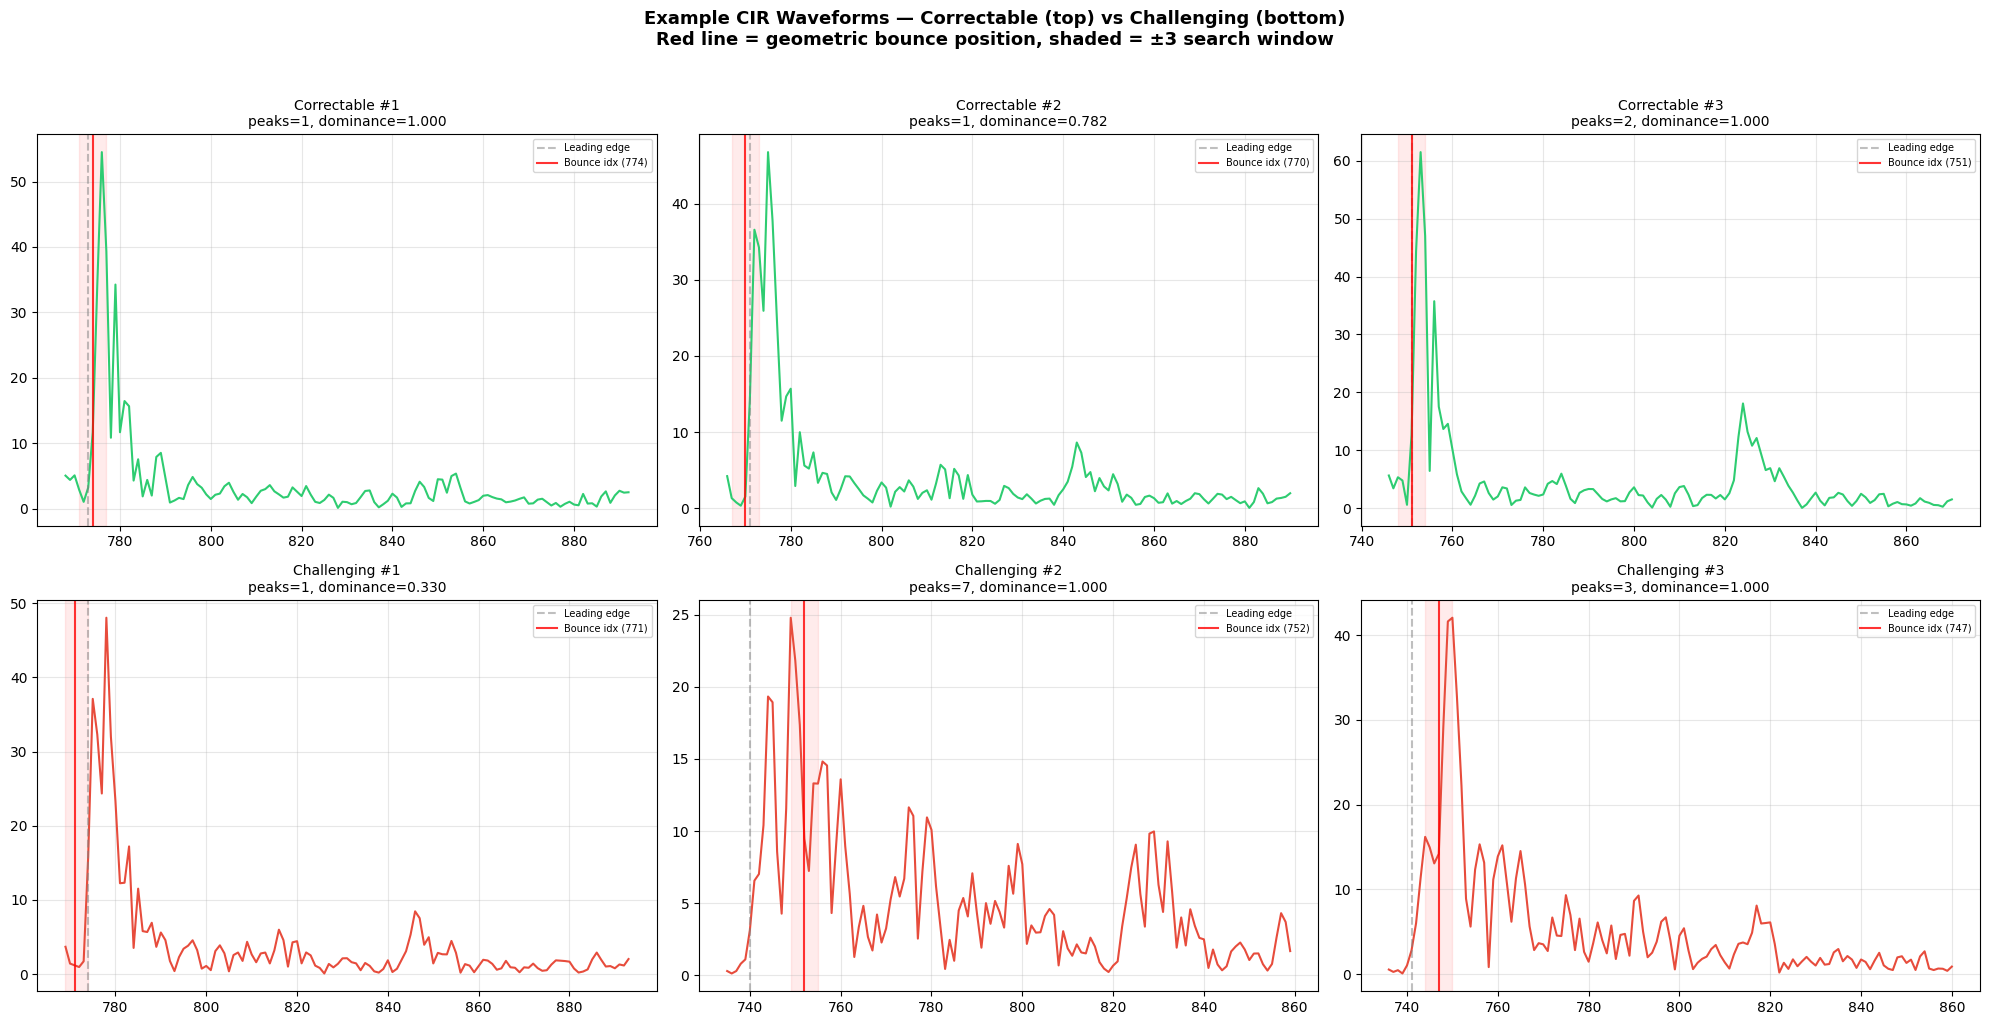

In [7]:
# Example CIR waveforms (correctable vs challenging)
fig, axs = plt.subplots(2, 3, figsize=(20, 10))
plt.subplots_adjust(hspace=0.45, wspace=0.3)

W = CONFIG['bounce_search_window']
correctable_idx = np.where(quality_labels == 0)[0]
challenging_idx = np.where(quality_labels == 1)[0]

# Show 3 correctable examples (spread across dataset for diversity)
for col in range(3):
    if col >= len(correctable_idx):
        axs[0, col].axis('off')
        continue
    step = max(1, len(correctable_idx) // 3)
    idx = correctable_idx[min(col * step, len(correctable_idx) - 1)]
    sig = raw_sigs[idx]
    le = leading_edges[idx]
    bpi = float(nlos_df.iloc[idx].get('bounce_path_idx', np.nan))
    bounce_idx = int(round(bpi)) if not np.isnan(bpi) else None

    roi_start = max(0, le - 5)
    roi_end = min(len(sig), le + 120)
    x_range = np.arange(roi_start, roi_end)

    ax = axs[0, col]
    ax.plot(x_range, sig[roi_start:roi_end], color='#2ecc71', lw=1.5)
    ax.axvline(le, color='gray', ls='--', alpha=0.5, label='Leading edge')
    if bounce_idx is not None:
        ax.axvline(bounce_idx, color='red', ls='-', lw=1.5, alpha=0.8,
                   label=f'Bounce idx ({bounce_idx})')
        ax.axvspan(max(roi_start, bounce_idx - W), min(roi_end, bounce_idx + W),
                   color='red', alpha=0.08)
    ax.set_title(f"Correctable #{col+1}\n"
                 f"peaks={num_peaks[idx]}, dominance={bounce_dominance[idx]:.3f}",
                 fontsize=10)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

# Show 3 challenging examples (spread across dataset)
for col in range(3):
    if col >= len(challenging_idx):
        axs[1, col].axis('off')
        continue
    step = max(1, len(challenging_idx) // 3)
    idx = challenging_idx[min(col * step, len(challenging_idx) - 1)]
    sig = raw_sigs[idx]
    le = leading_edges[idx]
    bpi = float(nlos_df.iloc[idx].get('bounce_path_idx', np.nan))
    bounce_idx = int(round(bpi)) if not np.isnan(bpi) else None

    roi_start = max(0, le - 5)
    roi_end = min(len(sig), le + 120)
    x_range = np.arange(roi_start, roi_end)

    ax = axs[1, col]
    ax.plot(x_range, sig[roi_start:roi_end], color='#e74c3c', lw=1.5)
    ax.axvline(le, color='gray', ls='--', alpha=0.5, label='Leading edge')
    if bounce_idx is not None:
        ax.axvline(bounce_idx, color='red', ls='-', lw=1.5, alpha=0.8,
                   label=f'Bounce idx ({bounce_idx})')
        ax.axvspan(max(roi_start, bounce_idx - W), min(roi_end, bounce_idx + W),
                   color='red', alpha=0.08)
    ax.set_title(f"Challenging #{col+1}\n"
                 f"peaks={num_peaks[idx]}, dominance={bounce_dominance[idx]:.3f}",
                 fontsize=10)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle(f"Example CIR Waveforms — Correctable (top) vs Challenging (bottom)\n"
             f"Red line = geometric bounce position, shaded = ±{W} search window",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 5. Annotated Single-Bounce CIR

Every NLOS scenario is a single reflection, TX -> wall or pillar -> RX. Two positions are marked on the CIR:

- `los_path_idx` (blue dashed): where the direct path would arrive if it were not blocked (distance `d_direct`)
- `bounce_path_idx` (red solid): where the reflected path arrives (distance `d_bounce`)

The gap between them is the NLOS ranging bias, the extra length of the reflected path. The plot shows one sample from each NLOS scenario.

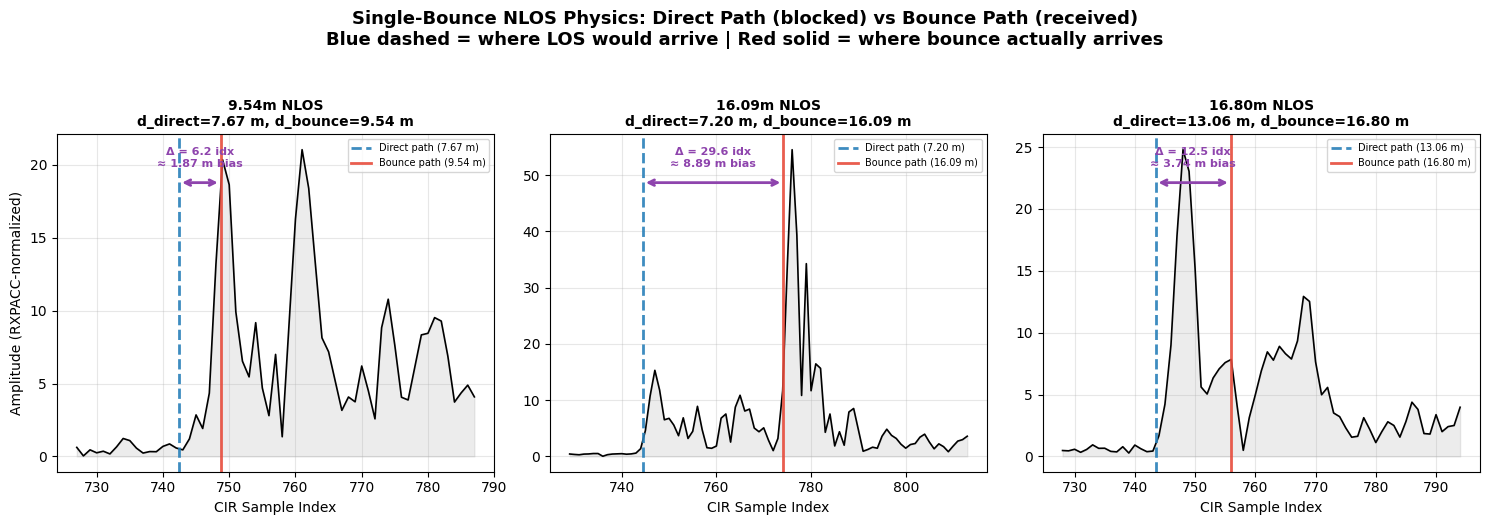


Scenario     d_direct (m)   d_bounce (m)   Bias (m)   Delay (idx) 
──────────────────────────────────────────────────────────────
9.54m        7.668          9.54           1.872      6.2         
16.09m       7.201          16.09          8.889      29.6        
16.80m       13.060         16.80          3.740      12.5        


In [8]:
# Annotated single-bounce NLOS CIR
# One representative sample per NLOS scenario, showing both LOS and bounce path positions

M_PER_INDEX = 0.3003  # c * 1.0016 ns per sample

# Group by scenario
scenarios = {}
for i, row in nlos_df.iterrows():
    sf = str(row['Source_File'])
    match = re.search(r'([\d.]+)m_nlos', sf)
    if match:
        key = match.group(1) + 'm'
        local_idx = i - nlos_df.index[0]  # convert to 0-based index into raw_sigs
        if key not in scenarios:
            scenarios[key] = local_idx

scenario_keys = sorted(scenarios.keys(), key=lambda k: float(k.replace('m', '')))
n_scenarios = len(scenario_keys)

fig, axs = plt.subplots(1, n_scenarios, figsize=(5 * n_scenarios, 5), sharey=False)
if n_scenarios == 1:
    axs = [axs]

for col, key in enumerate(scenario_keys):
    idx = scenarios[key]
    row = nlos_df.iloc[idx]
    sig = raw_sigs[idx]
    le = leading_edges[idx]

    los_idx = float(row['los_path_idx'])
    bounce_idx = float(row['bounce_path_idx'])
    d_direct = float(row['d_direct'])
    d_bounce = float(row['d_bounce'])
    bias_m = d_bounce - d_direct
    delay_samples = bounce_idx - los_idx

    # Show a wider window to capture both markers
    view_start = max(0, int(los_idx) - 15)
    view_end = min(len(sig), int(bounce_idx) + 40)
    x_range = np.arange(view_start, view_end)

    ax = axs[col]
    # CIR waveform
    ax.fill_between(x_range, sig[view_start:view_end], alpha=0.15, color='gray')
    ax.plot(x_range, sig[view_start:view_end], color='k', lw=1.2)

    # LOS path position (where the direct path would arrive if unobstructed)
    ax.axvline(los_idx, color='#2980b9', ls='--', lw=2, alpha=0.9,
               label=f'Direct path ({d_direct:.2f} m)')

    # Bounce path position (where the reflection actually arrives)
    ax.axvline(bounce_idx, color='#e74c3c', ls='-', lw=2, alpha=0.9,
               label=f'Bounce path ({d_bounce:.2f} m)')

    # Annotate the delay gap
    y_arrow = ax.get_ylim()[1] * 0.85
    ax.annotate('', xy=(bounce_idx, y_arrow), xytext=(los_idx, y_arrow),
                arrowprops=dict(arrowstyle='<->', color='#8e44ad', lw=2))
    mid_x = (los_idx + bounce_idx) / 2
    ax.text(mid_x, y_arrow * 1.05,
            f'Δ = {delay_samples:.1f} idx\n≈ {bias_m:.2f} m bias',
            ha='center', va='bottom', fontsize=8, fontweight='bold', color='#8e44ad')

    ax.set_title(f'{key} NLOS\n'
                 f'd_direct={d_direct:.2f} m, d_bounce={d_bounce:.2f} m',
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('CIR Sample Index')
    if col == 0:
        ax.set_ylabel('Amplitude (RXPACC-normalized)')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, alpha=0.3)

fig.suptitle('Single-Bounce NLOS Physics: Direct Path (blocked) vs Bounce Path (received)\n'
             'Blue dashed = where LOS would arrive | Red solid = where bounce actually arrives',
             fontsize=13, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'Scenario':<12} {'d_direct (m)':<14} {'d_bounce (m)':<14} {'Bias (m)':<10} {'Delay (idx)':<12}")
print('─' * 62)
for key in scenario_keys:
    idx = scenarios[key]
    row = nlos_df.iloc[idx]
    d_dir = float(row['d_direct'])
    d_bnc = float(row['d_bounce'])
    los_i = float(row['los_path_idx'])
    bnc_i = float(row['bounce_path_idx'])
    print(f"{key:<12} {d_dir:<14.3f} {d_bnc:<14.2f} {d_bnc - d_dir:<10.3f} {bnc_i - los_i:<12.1f}")

---
## 6. Train and Evaluate (70/30 Split)

The random forest is trained on 70% of the NLOS samples (stratified) and tested on the other 30%, which gives the in-distribution result.

In [9]:
# Train and evaluate on a 70/30 stratified split
X_all = embeddings  # (N, 64)
y_all = quality_labels
FEATURE_DIM = EMBEDDING_DIM
FEATURE_NAMES = EMBEDDING_NAMES

# Extract scenario label for each NLOS sample (for per-scenario breakdown)
scenario_labels = np.array([
    re.search(r'([\d.]+)m_nlos', str(sf)).group(1) + 'm'
    if re.search(r'([\d.]+)m_nlos', str(sf)) else 'unknown'
    for sf in nlos_df['Source_File'].values
])
unique_scenarios = sorted(set(scenario_labels), key=lambda x: float(x.replace('m', '')))

print(f"Total NLOS samples: {len(y_all)}")
print(f"  Correctable: {int(np.sum(y_all == 0))}, Challenging: {int(np.sum(y_all == 1))}")
print(f"NLOS scenarios: {unique_scenarios}")
for sc in unique_scenarios:
    mask = scenario_labels == sc
    n_corr = int(np.sum(y_all[mask] == 0))
    n_chal = int(np.sum(y_all[mask] == 1))
    print(f"  {sc:>8s}: {mask.sum()} samples (Correctable={n_corr}, Challenging={n_chal})")

# 70/30 stratified split
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_all, y_all, np.arange(len(y_all)),
    test_size=0.30,
    stratify=y_all,
    random_state=CONFIG["seed"]
)
scenario_test = scenario_labels[idx_test]

print(f"\nSplit: Train={len(X_train)} (70%), Test={len(X_test)} (30%)")
print(f"  Train — Correctable: {int(np.sum(y_train == 0))}, Challenging: {int(np.sum(y_train == 1))}")
print(f"  Test  — Correctable: {int(np.sum(y_test == 0))}, Challenging: {int(np.sum(y_test == 1))}")

# Train RF
rf_model = RandomForestClassifier(
    n_estimators=CONFIG["n_estimators"],
    max_depth=CONFIG["max_depth"],
    min_samples_split=CONFIG["min_samples_split"],
    min_samples_leaf=CONFIG["min_samples_leaf"],
    class_weight="balanced",
    random_state=CONFIG["seed"],
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

# Evaluate
y_pred = rf_model.predict(X_test)
test_acc = (y_test == y_pred).mean()
proba = rf_model.predict_proba(X_test)
y_prob = proba[:, 1] if proba.shape[1] > 1 else proba[:, 0]
fpr_test, tpr_test, _ = roc_curve(y_test, y_prob)
auc_test = auc(fpr_test, tpr_test)

print(f"\n{'=' * 60}")
print(f"70/30 SPLIT RESULTS — LNN {FEATURE_DIM}-dim → RF")
print(f"{'=' * 60}")
print(f"Overall Accuracy: {100*test_acc:.2f}%")
print(f"ROC AUC:          {auc_test:.4f}")
print()
print(classification_report(y_test, y_pred,
                             target_names=['Correctable', 'Challenging']))

# Per-scenario accuracy on test set
print("Per-scenario accuracy (test split):")
for sc in unique_scenarios:
    mask = scenario_test == sc
    if mask.sum() > 0:
        sc_acc = (y_test[mask] == y_pred[mask]).mean()
        print(f"  {sc:>8s} NLOS: {100*sc_acc:.1f}% (n={mask.sum()})")

Total NLOS samples: 1800
  Correctable: 506, Challenging: 1294
NLOS scenarios: [np.str_('9.54m'), np.str_('16.09m'), np.str_('16.80m')]
     9.54m: 600 samples (Correctable=49, Challenging=551)
    16.09m: 600 samples (Correctable=457, Challenging=143)
    16.80m: 600 samples (Correctable=0, Challenging=600)

Split: Train=1260 (70%), Test=540 (30%)
  Train — Correctable: 354, Challenging: 906
  Test  — Correctable: 152, Challenging: 388



70/30 SPLIT RESULTS — LNN 64-dim → RF
Overall Accuracy: 93.33%
ROC AUC:          0.9762

              precision    recall  f1-score   support

 Correctable       0.88      0.88      0.88       152
 Challenging       0.95      0.95      0.95       388

    accuracy                           0.93       540
   macro avg       0.92      0.92      0.92       540
weighted avg       0.93      0.93      0.93       540

Per-scenario accuracy (test split):
     9.54m NLOS: 92.7% (n=192)
    16.09m NLOS: 88.4% (n=190)
    16.80m NLOS: 100.0% (n=158)


---
## 7. Diagnostics (70/30 Split)

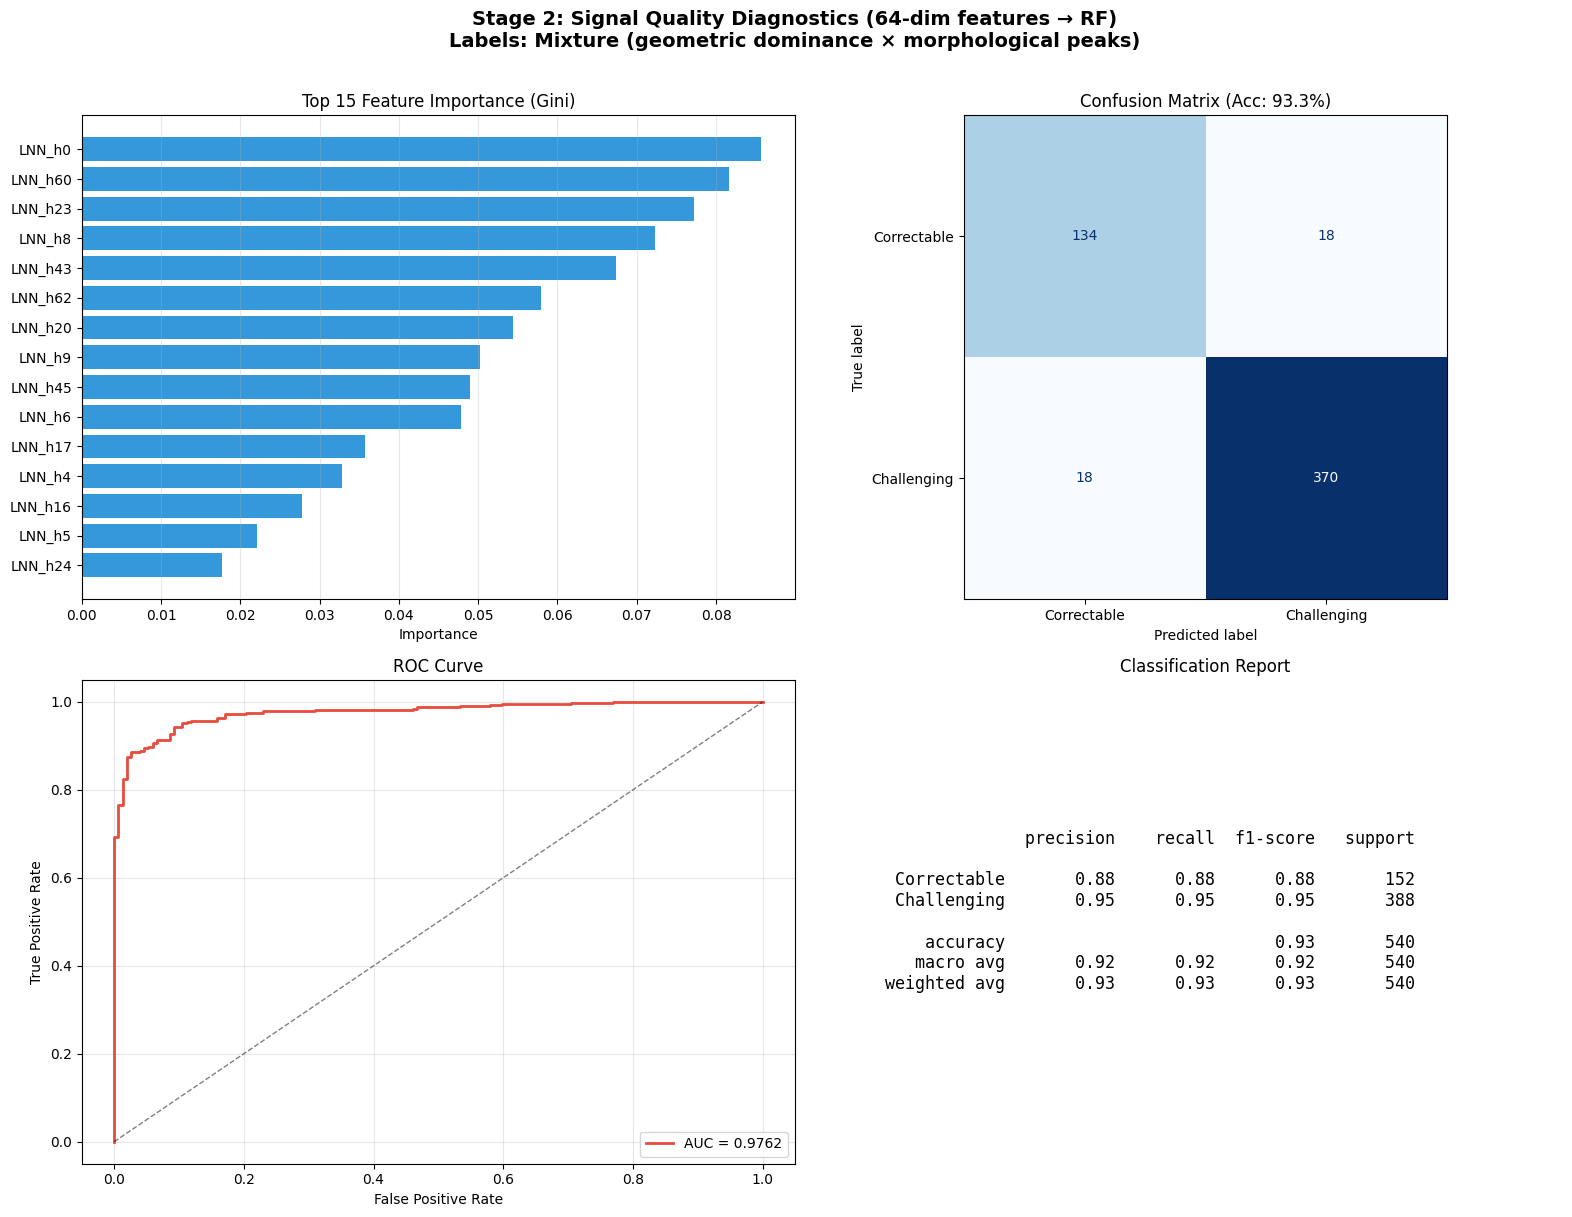


Top 15 Feature Importance (ranked):
  LNN_h0                    0.0857
  LNN_h60                   0.0817
  LNN_h23                   0.0772
  LNN_h8                    0.0723
  LNN_h43                   0.0674
  LNN_h62                   0.0579
  LNN_h20                   0.0544
  LNN_h9                    0.0502
  LNN_h45                   0.0490
  LNN_h6                    0.0478
  LNN_h17                   0.0357
  LNN_h4                    0.0328
  LNN_h16                   0.0278
  LNN_h5                    0.0221
  LNN_h24                   0.0177


In [10]:
# Diagnostics
y_pred_diag = rf_model.predict(X_test)

proba_diag = rf_model.predict_proba(X_test)
if proba_diag.shape[1] > 1:
    y_prob_diag = proba_diag[:, 1]
else:
    y_prob_diag = proba_diag[:, 0]

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

# 1. Feature Importance (top 15 dims)
ax = axs[0, 0]
importances = rf_model.feature_importances_
top_k = min(15, len(importances))
sorted_idx = np.argsort(importances)[-top_k:]
ax.barh(np.array(FEATURE_NAMES)[sorted_idx], importances[sorted_idx], color='#3498db')
ax.set_title(f"Top {top_k} Feature Importance (Gini)")
ax.set_xlabel("Importance")
ax.grid(True, alpha=0.3, axis='x')

# 2. Confusion Matrix
ax = axs[0, 1]
cm = confusion_matrix(y_test, y_pred_diag)
disp = ConfusionMatrixDisplay(cm, display_labels=['Correctable', 'Challenging'])
disp.plot(ax=ax, cmap='Blues', colorbar=False)
acc = (y_test == y_pred_diag).mean()
ax.set_title(f"Confusion Matrix (Acc: {100*acc:.1f}%)")

# 3. ROC Curve
ax = axs[1, 0]
if len(np.unique(y_test)) > 1:
    fpr, tpr, _ = roc_curve(y_test, y_prob_diag)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color='#e74c3c', lw=2, label=f'AUC = {roc_auc:.4f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
    ax.set_title("ROC Curve")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc='lower right')
else:
    ax.text(0.5, 0.5, 'Single class in test set', ha='center', va='center', fontsize=12)
    ax.set_title("ROC Curve (N/A)")
ax.grid(True, alpha=0.3)

# 4. Classification Report
ax = axs[1, 1]
report_text = classification_report(y_test, y_pred_diag,
                               target_names=['Correctable', 'Challenging'])
ax.text(0.05, 0.5, report_text, fontsize=12, fontfamily='monospace',
        verticalalignment='center', transform=ax.transAxes)
ax.set_title("Classification Report")
ax.axis('off')

plt.suptitle(f"Stage 2: Signal Quality Diagnostics ({FEATURE_DIM}-dim features → RF)\n"
             f"Labels: Mixture (geometric dominance × morphological peaks)",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Print top features
print(f"\nTop 15 Feature Importance (ranked):")
for feat, imp in sorted(zip(FEATURE_NAMES, importances), key=lambda x: -x[1])[:15]:
    print(f"  {feat:<25} {imp:.4f}")

---
## 8. Model Comparison

Random forest compared with XGBoost, logistic regression, SVM and a decision tree on the same 70/30 split.

In [11]:
# Model comparison: RF, XGBoost, logistic regression, SVM and decision tree
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Models to compare (RF already trained above)
models = {
    "Random Forest": rf_model,
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        use_label_encoder=False, eval_metric='logloss',
        random_state=CONFIG["seed"], n_jobs=-1,
    ),
    "Logistic Reg.": Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=CONFIG["seed"]))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel='rbf', C=10, class_weight='balanced', probability=True, random_state=CONFIG["seed"]))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, class_weight='balanced', random_state=CONFIG["seed"]
    ),
}

# Train & evaluate each model
results = {}
model_predictions = {}

for name, model in models.items():
    if name == "Random Forest":
        y_pred_m = y_pred
        y_prob_m = y_prob
    else:
        model.fit(X_train, y_train)
        y_pred_m = model.predict(X_test)
        proba_m = model.predict_proba(X_test)
        y_prob_m = proba_m[:, 1] if proba_m.shape[1] > 1 else proba_m[:, 0]

    acc = (y_test == y_pred_m).mean()
    fpr_m, tpr_m, _ = roc_curve(y_test, y_prob_m)
    auc_m = auc(fpr_m, tpr_m)
    cm_m = confusion_matrix(y_test, y_pred_m)
    # Precision, recall, f1 for each class
    report = classification_report(y_test, y_pred_m,
                                   target_names=['Correctable', 'Challenging'],
                                   output_dict=True)

    results[name] = {
        "Accuracy": acc,
        "AUC": auc_m,
        "F1 (Corr.)": report['Correctable']['f1-score'],
        "F1 (Chal.)": report['Challenging']['f1-score'],
        "F1 (macro)": report['macro avg']['f1-score'],
    }
    model_predictions[name] = {"y_pred": y_pred_m, "y_prob": y_prob_m, "fpr": fpr_m, "tpr": tpr_m}

# Display results table
print(f"{'Model':<18} {'Acc':>8} {'AUC':>8} {'F1(Corr)':>10} {'F1(Chal)':>10} {'F1(macro)':>10}")
print("-" * 68)
for name, r in results.items():
    print(f"{name:<18} {100*r['Accuracy']:>7.2f}% {r['AUC']:>8.4f} {r['F1 (Corr.)']:>10.4f} {r['F1 (Chal.)']:>10.4f} {r['F1 (macro)']:>10.4f}")

C:\Users\preca\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:43:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Model                   Acc      AUC   F1(Corr)   F1(Chal)  F1(macro)
--------------------------------------------------------------------
Random Forest        93.33%   0.9762     0.8816     0.9536     0.9176
XGBoost              92.04%   0.9781     0.8599     0.9444     0.9022
Logistic Reg.        91.85%   0.9615     0.8608     0.9424     0.9016
SVM (RBF)            92.78%   0.9785     0.8754     0.9492     0.9123
Decision Tree        91.85%   0.9081     0.8581     0.9429     0.9005


C:\Users\preca\AppData\Local\Temp\ipykernel_11576\441674915.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=25, ha='right', fontsize=9)


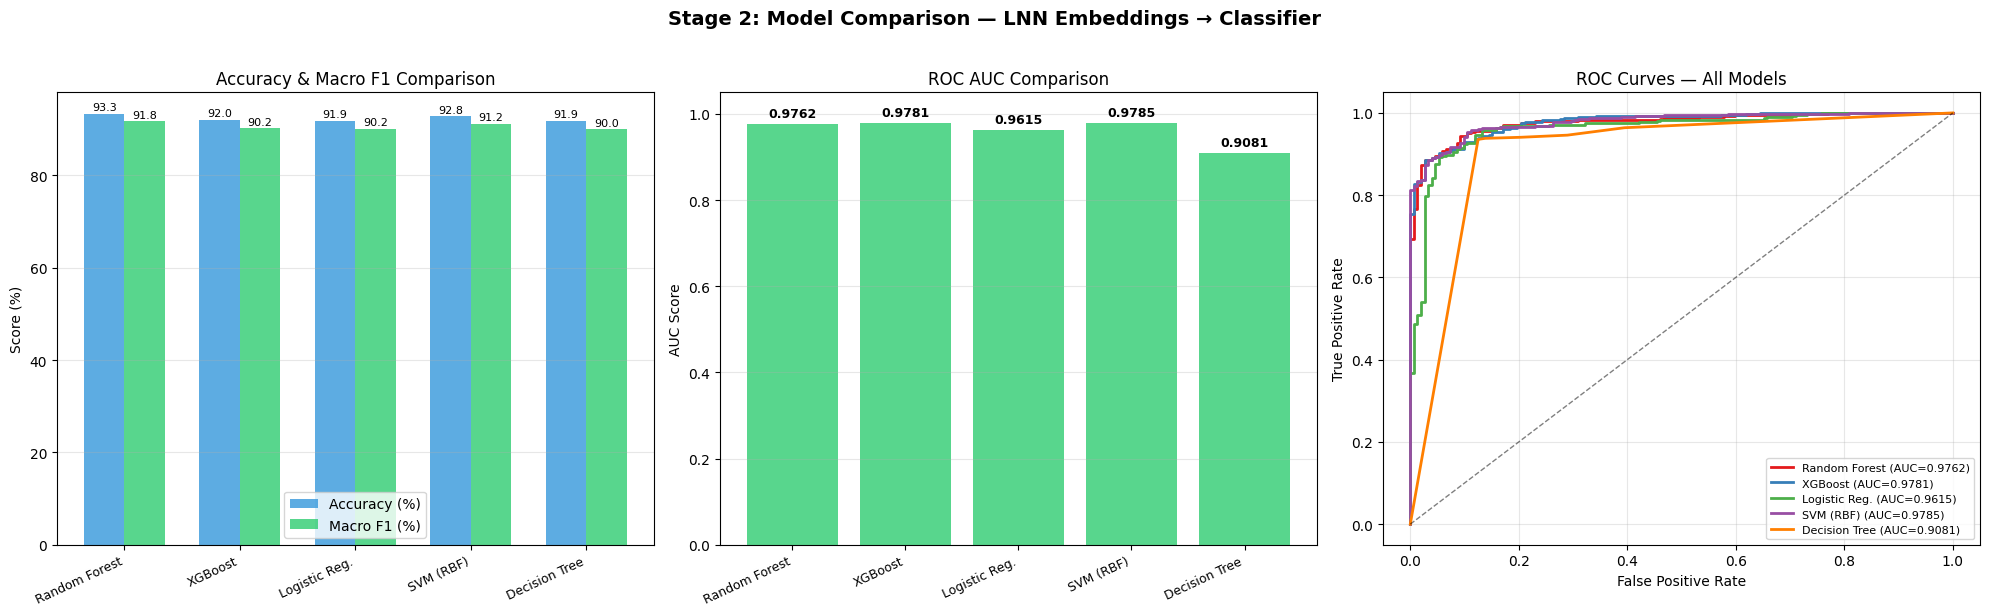


Best by Accuracy:  Random Forest (93.33%)
Best by AUC:       SVM (RBF) (0.9785)
Best by Macro F1:  Random Forest (0.9176)


In [12]:
# Model comparison visualization
model_names = list(results.keys())
accs = [results[n]["Accuracy"] for n in model_names]
aucs = [results[n]["AUC"] for n in model_names]
f1_macros = [results[n]["F1 (macro)"] for n in model_names]

fig, axs = plt.subplots(1, 3, figsize=(20, 6))

# 1. Accuracy & Macro F1 comparison
ax = axs[0]
x = np.arange(len(model_names))
w = 0.35
bars1 = ax.bar(x - w/2, [a * 100 for a in accs], w, color='#3498db', alpha=0.8, label='Accuracy (%)')
bars2 = ax.bar(x + w/2, [f * 100 for f in f1_macros], w, color='#2ecc71', alpha=0.8, label='Macro F1 (%)')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=25, ha='right', fontsize=9)
ax.set_ylabel('Score (%)')
ax.set_title('Accuracy & Macro F1 Comparison')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)

# 2. AUC comparison
ax = axs[1]
colors = ['#e74c3c' if a < 0.7 else '#f39c12' if a < 0.85 else '#2ecc71' for a in aucs]
bars = ax.bar(model_names, aucs, color=colors, alpha=0.8)
ax.set_xticklabels(model_names, rotation=25, ha='right', fontsize=9)
ax.set_ylabel('AUC Score')
ax.set_title('ROC AUC Comparison')
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 1.05)
for bar, val in zip(bars, aucs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. ROC curves overlay
ax = axs[2]
cmap = plt.cm.Set1
for idx, name in enumerate(model_names):
    fpr_m = model_predictions[name]["fpr"]
    tpr_m = model_predictions[name]["tpr"]
    auc_m = results[name]["AUC"]
    ax.plot(fpr_m, tpr_m, lw=2, color=cmap(idx), label=f'{name} (AUC={auc_m:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Models')
ax.legend(fontsize=8, loc='lower right')
ax.grid(True, alpha=0.3)

plt.suptitle('Stage 2: Model Comparison — LNN Embeddings → Classifier',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Best model summary
best_acc = max(results, key=lambda n: results[n]["Accuracy"])
best_auc = max(results, key=lambda n: results[n]["AUC"])
best_f1 = max(results, key=lambda n: results[n]["F1 (macro)"])
print(f"\nBest by Accuracy:  {best_acc} ({100*results[best_acc]['Accuracy']:.2f}%)")
print(f"Best by AUC:       {best_auc} ({results[best_auc]['AUC']:.4f})")
print(f"Best by Macro F1:  {best_f1} ({results[best_f1]['F1 (macro)']:.4f})")

---
## 9. Unseen Dataset Evaluation (All Models)

All five models are tested on `unseen_dataset.csv`, which has two NLOS scenarios (8.91m and 12.79m) that were never used for training. This is the out-of-distribution result.

Loading: ../dataset/channels/unseen_dataset.csv
  Total samples: 2400, NLOS samples: 1200



  Mixture labeling (amplitude ratio >= 50% AND peaks <= 2):
    ──────────────────────────────────────────────────
    Correctable (clean bounce):     406 (33.8%)
    Challenging (multipath/noisy):   794 (66.2%)
    ──────────────────────────────────────────────────
    Bounce dominance stats — mean: 0.851, median: 1.000
    Peak count stats — mean: 3.91, max: 10
    Strongest peak power stats — mean: 18.6895, min: 5.9535, max: 49.7966

Unseen NLOS samples: 1200
  Correctable: 406, Challenging: 794


  Unseen embeddings shape: (1200, 64)

UNSEEN DATASET: LNN 64-dim → All Models
Dataset: unseen_dataset.csv (1200 NLOS samples)

Model                   Acc      AUC   F1(Corr)   F1(Chal)  F1(macro)
--------------------------------------------------------------------
Random Forest        82.08%   0.8641     0.7152     0.8693     0.7923
XGBoost              79.25%   0.8552     0.6693     0.8488     0.7591
Logistic Reg.        75.42%   0.8717     0.5908     0.8243     0.7076
SVM (RBF)            81.17%   0.8569     0.7132     0.8598     0.7865
Decision Tree        78.33%   0.7011     0.5860     0.8533     0.7196

Per-scenario accuracy (unseen):
  Scenario       Random Forest         XGBoost   Logistic Reg.       SVM (RBF)   Decision Tree
  --------------------------------------------------------------------------------------------
  8.91m NLOS             89.0%           87.2%           86.2%           86.5%           91.0%
  12.79m NLOS            75.2%           71.3%           64.7%   

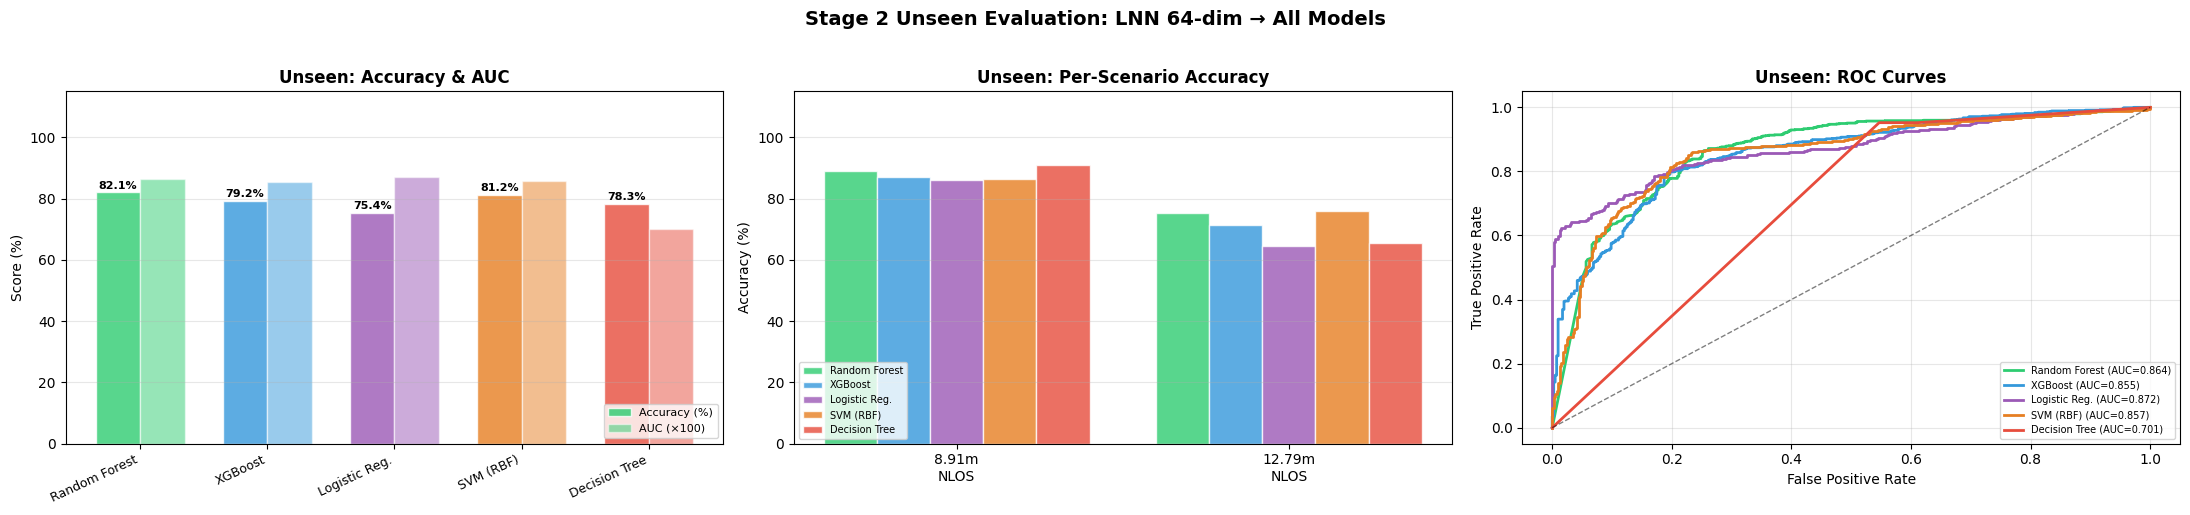

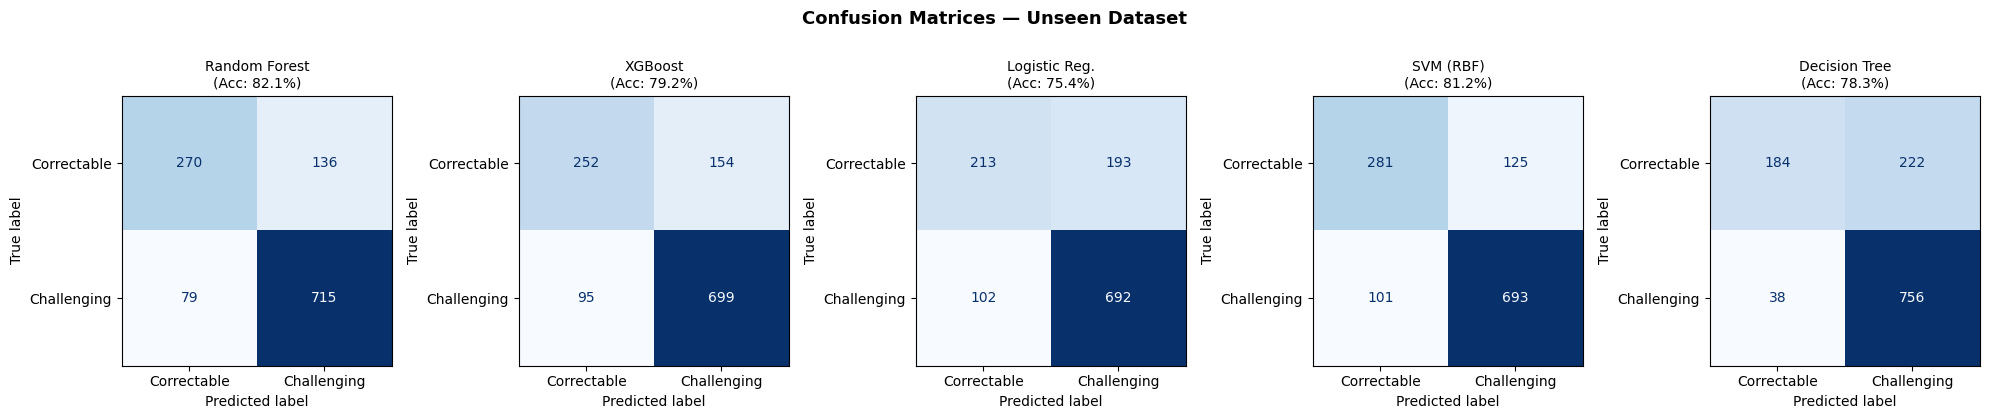


SUMMARY: Test Split vs Unseen Dataset

Model                Test Acc   Test AUC   Unseen Acc   Unseen AUC
-----------------------------------------------------------------
Random Forest          93.33%     0.9762       82.08%       0.8641
XGBoost                92.04%     0.9781       79.25%       0.8552
Logistic Reg.          91.85%     0.9615       75.42%       0.8717
SVM (RBF)              92.78%     0.9785       81.17%       0.8569
Decision Tree          91.85%     0.9081       78.33%       0.7011


In [13]:
# Unseen dataset evaluation (all models)
unseen_filepath = "../dataset/channels/unseen_dataset.csv"

# Load and process unseen NLOS data
(unseen_raw_sigs, unseen_leading_edges, unseen_nlos_df,
 unseen_labels, unseen_num_peaks, unseen_bounce_dom,
 unseen_spp) = load_nlos_features(unseen_filepath)

print(f"\nUnseen NLOS samples: {len(unseen_labels)}")
print(f"  Correctable: {int(np.sum(unseen_labels==0))}, Challenging: {int(np.sum(unseen_labels==1))}")

# Extract LNN embeddings for unseen data
unseen_cir_sequences = []
for i in range(len(unseen_raw_sigs)):
    crop = preprocess_cir_for_lnn(unseen_raw_sigs[i], unseen_leading_edges[i])
    unseen_cir_sequences.append(crop)

unseen_cir_tensor = torch.tensor(
    np.array(unseen_cir_sequences).reshape(-1, STAGE1_CONFIG['total_len'], 1),
    dtype=torch.float32
).to(device)

unseen_embeddings_list = []
with torch.no_grad():
    for i in range(0, len(unseen_cir_tensor), 256):
        batch_cir = unseen_cir_tensor[i:i+256]
        emb = lnn_encoder.embed(batch_cir)
        unseen_embeddings_list.append(emb.cpu().numpy())

unseen_embeddings = np.vstack(unseen_embeddings_list)
print(f"  Unseen embeddings shape: {unseen_embeddings.shape}")

# Features & labels
X_unseen = unseen_embeddings  # (N, 64)
y_unseen = unseen_labels

# Per-scenario labels
unseen_scenarios = np.array([
    re.search(r'([\d.]+)m_nlos', str(sf)).group(1) + 'm'
    if re.search(r'([\d.]+)m_nlos', str(sf)) else 'unknown'
    for sf in unseen_nlos_df['Source_File'].values
])
unseen_unique_scenarios = sorted(set(unseen_scenarios), key=lambda x: float(x.replace('m', '')))

# Evaluate all models on the unseen data
unseen_results = {}
unseen_predictions = {}

for name, model in models.items():
    y_pred_m = model.predict(X_unseen)
    proba_m = model.predict_proba(X_unseen)
    y_prob_m = proba_m[:, 1] if proba_m.shape[1] > 1 else proba_m[:, 0]

    acc_m = (y_unseen == y_pred_m).mean()
    fpr_m, tpr_m, _ = roc_curve(y_unseen, y_prob_m)
    auc_m = auc(fpr_m, tpr_m)
    report_m = classification_report(y_unseen, y_pred_m,
                                     target_names=['Correctable', 'Challenging'],
                                     output_dict=True)

    # Per-scenario accuracy
    per_scenario = {}
    for sc in unseen_unique_scenarios:
        mask = unseen_scenarios == sc
        if mask.sum() > 0:
            per_scenario[sc] = (y_unseen[mask] == y_pred_m[mask]).mean()

    unseen_results[name] = {
        "Accuracy": acc_m,
        "AUC": auc_m,
        "F1 (Corr.)": report_m['Correctable']['f1-score'],
        "F1 (Chal.)": report_m['Challenging']['f1-score'],
        "F1 (macro)": report_m['macro avg']['f1-score'],
        "Per-scenario": per_scenario,
    }
    unseen_predictions[name] = {"y_pred": y_pred_m, "y_prob": y_prob_m, "fpr": fpr_m, "tpr": tpr_m}

# Keep the RF results for the summary cell
y_pred_unseen = unseen_predictions["Random Forest"]["y_pred"]
acc_unseen = unseen_results["Random Forest"]["Accuracy"]
auc_u = unseen_results["Random Forest"]["AUC"]

# Print comparison table
print("\n" + "=" * 80)
print(f"UNSEEN DATASET: LNN {FEATURE_DIM}-dim → All Models")
print(f"Dataset: unseen_dataset.csv ({len(y_unseen)} NLOS samples)")
print("=" * 80)
print(f"\n{'Model':<18} {'Acc':>8} {'AUC':>8} {'F1(Corr)':>10} {'F1(Chal)':>10} {'F1(macro)':>10}")
print("-" * 68)
for name, r in unseen_results.items():
    print(f"{name:<18} {100*r['Accuracy']:>7.2f}% {r['AUC']:>8.4f} {r['F1 (Corr.)']:>10.4f} {r['F1 (Chal.)']:>10.4f} {r['F1 (macro)']:>10.4f}")

# Per-scenario breakdown
print(f"\nPer-scenario accuracy (unseen):")
header = f"  {'Scenario':<12}" + "".join(f"{name:>16}" for name in unseen_results)
print(header)
print("  " + "-" * (12 + 16 * len(unseen_results)))
for sc in unseen_unique_scenarios:
    row = f"  {sc + ' NLOS':<12}"
    for name, r in unseen_results.items():
        sc_acc = r["Per-scenario"].get(sc, 0)
        row += f"{100*sc_acc:>15.1f}%"
    print(row)

# Visualization
model_names_u = list(unseen_results.keys())
n_models = len(model_names_u)
colors = ['#2ecc71', '#3498db', '#9b59b6', '#e67e22', '#e74c3c']

fig, axs = plt.subplots(1, 3, figsize=(22, 5))
plt.subplots_adjust(wspace=0.35)

# Plot 1: Accuracy & AUC comparison
ax = axs[0]
accs_u = [unseen_results[n]["Accuracy"] for n in model_names_u]
aucs_u = [unseen_results[n]["AUC"] for n in model_names_u]
x = np.arange(n_models)
w = 0.35
bars1 = ax.bar(x - w/2, [100*v for v in accs_u], w, label='Accuracy (%)', color=colors, alpha=0.8, edgecolor='white')
bars2 = ax.bar(x + w/2, [100*v for v in aucs_u], w, label='AUC (\u00d7100)', color=colors, alpha=0.5, edgecolor='white')
for bar, val in zip(bars1, accs_u):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{100*val:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names_u, rotation=25, ha='right', fontsize=9)
ax.set_ylabel('Score (%)')
ax.set_title('Unseen: Accuracy & AUC', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 115)

# Plot 2: Per-scenario accuracy (grouped bar)
ax = axs[1]
n_sc = len(unseen_unique_scenarios)
x_sc = np.arange(n_sc)
bar_width = 0.8 / n_models
for idx, name in enumerate(model_names_u):
    sc_accs = [unseen_results[name]["Per-scenario"].get(sc, 0) for sc in unseen_unique_scenarios]
    offset = (idx - n_models/2 + 0.5) * bar_width
    bars = ax.bar(x_sc + offset, [100*v for v in sc_accs], bar_width,
                  label=name, color=colors[idx], alpha=0.8, edgecolor='white')
ax.set_xticks(x_sc)
ax.set_xticklabels([f'{s}\nNLOS' for s in unseen_unique_scenarios], fontsize=10)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Unseen: Per-Scenario Accuracy', fontsize=12, fontweight='bold')
ax.legend(fontsize=7, loc='lower left')
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 115)

# Plot 3: ROC Curves (all models)
ax = axs[2]
for idx, name in enumerate(model_names_u):
    fpr_m = unseen_predictions[name]["fpr"]
    tpr_m = unseen_predictions[name]["tpr"]
    auc_m = unseen_results[name]["AUC"]
    ax.plot(fpr_m, tpr_m, color=colors[idx], lw=2, label=f'{name} (AUC={auc_m:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Unseen: ROC Curves', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=7)
ax.grid(True, alpha=0.3)

plt.suptitle(f'Stage 2 Unseen Evaluation: LNN {FEATURE_DIM}-dim \u2192 All Models',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Confusion matrices (all models)
fig, axs_cm = plt.subplots(1, n_models, figsize=(4*n_models, 4))
for idx, name in enumerate(model_names_u):
    ax = axs_cm[idx]
    cm_m = confusion_matrix(y_unseen, unseen_predictions[name]["y_pred"])
    disp_m = ConfusionMatrixDisplay(cm_m, display_labels=['Correctable', 'Challenging'])
    disp_m.plot(ax=ax, cmap='Blues', colorbar=False)
    acc_m = unseen_results[name]["Accuracy"]
    ax.set_title(f"{name}\n(Acc: {100*acc_m:.1f}%)", fontsize=10)
plt.suptitle(f'Confusion Matrices \u2014 Unseen Dataset', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Summary table: Test vs Unseen
print("\n" + "=" * 80)
print("SUMMARY: Test Split vs Unseen Dataset")
print("=" * 80)
print(f"\n{'Model':<18} {'Test Acc':>10} {'Test AUC':>10} {'Unseen Acc':>12} {'Unseen AUC':>12}")
print("-" * 65)
for name in model_names_u:
    t_acc = results[name]["Accuracy"]
    t_auc = results[name]["AUC"]
    u_acc = unseen_results[name]["Accuracy"]
    u_auc = unseen_results[name]["AUC"]
    print(f"{name:<18} {100*t_acc:>9.2f}% {t_auc:>10.4f} {100*u_acc:>11.2f}% {u_auc:>12.4f}")

In [14]:
# Save unseen embeddings for reference notebook reproducibility
np.save("stage2_unseen_embeddings.npy", unseen_embeddings)
print(f"Saved unseen embeddings: {unseen_embeddings.shape} -> stage2_unseen_embeddings.npy")

Saved unseen embeddings: (1200, 64) -> stage2_unseen_embeddings.npy


In [15]:
print("=" * 60)
print("Stage 2 — Summary")
print("=" * 60)
print(f"Encoder dependency: stage1_pi_hlnn_best.pt (frozen DualCircuit_PI_HLNN)")
print()
print(f"Architecture: Frozen DualCircuit_PI_HLNN encoder → {FEATURE_DIM}-dim embeddings → RF classifier")
print(f"  LNN embeddings: {EMBEDDING_DIM}-dim (avg-pooled dual-circuit ODE states)")
print()
print(f"Results:")
print(f"  70\30 split (test): Acc={100*test_acc:.2f}%, AUC={auc_test:.4f}")
print(f"  Unseen dataset:     Acc={100*acc_unseen:.2f}%, AUC={auc_u:.4f}")
print()
print(f"Labels: MIXTURE (geometric + morphological)")
print(f"  Criterion 1: bounce dominance >= {CONFIG['dominance_threshold']:.0%}")
print(f"  Criterion 2: num_peaks <= {CONFIG['dominant_path_max_peaks']}")
print(f"  Correctable (0): BOTH conditions met")
print(f"  Challenging (1): either condition violated")
print()
print("Pipeline: Stage 1 (LNN) → Stage 2 (LNN embeddings → RF → signal quality) → Stage 3 (bounce distance)")

Stage 2 — Summary
Encoder dependency: stage1_pi_hlnn_best.pt (frozen DualCircuit_PI_HLNN)

Architecture: Frozen DualCircuit_PI_HLNN encoder → 64-dim embeddings → RF classifier
  LNN embeddings: 64-dim (avg-pooled dual-circuit ODE states)

Results:
  70 split (test): Acc=93.33%, AUC=0.9762
  Unseen dataset:     Acc=82.08%, AUC=0.8641

Labels: MIXTURE (geometric + morphological)
  Criterion 1: bounce dominance >= 50%
  Criterion 2: num_peaks <= 2
  Correctable (0): BOTH conditions met
  Challenging (1): either condition violated

Pipeline: Stage 1 (LNN) → Stage 2 (LNN embeddings → RF → signal quality) → Stage 3 (bounce distance)
